### 04_TM_replacement

In [1]:
import pandas as pd
import numpy as np
import os
import yaml

import sys
sys.path.append('../src/TAS2Rs_cofolding_utils/')
from complex_utils import get_ligands_interactions
from receptor_region import classify_hTAS2R_residue_region, ReceptorRegionClassyfier
from BW_numbers import TAS2Rs_BW_numbers
from msa import TAS2Rs_MSA
from other import read_json

import seaborn as sns
import matplotlib.patches as mpatches
palette = sns.color_palette('Set1')

### TM replacement

In [2]:
path_to_BW_numbers = '../data/hTAS2Rs_BW_numbers.xlsx'
BW_numbers = TAS2Rs_BW_numbers(path_to_BW_numbers)
path_to_msa = '../data/sequences/TAS2Rs T-Coffee aligned.fa'
msa = TAS2Rs_MSA(path_to_msa)

In [3]:
receptor_pairs = pd.DataFrame([{'source receptor': 'TAS2R14', 'target receptor': 'TAS2R43'},
                               {'source receptor': 'TAS2R43', 'target receptor': 'TAS2R14'}])
TM_numbers = list(range(1, 9, 1))

In [4]:
receptors_TM_replacement = []

for _, row in receptor_pairs.iterrows():
    
    source_receptor = row['source receptor']
    target_receptor = row['target receptor']

    source_sequence = str(msa.get_sequence(f'h{source_receptor}'))
    target_sequence = str(msa.get_sequence(f'h{target_receptor}'))

    for TM_number in TM_numbers:
        source_TM_sequence = BW_numbers.get_TM_sequence(receptor=source_receptor, TM_number=TM_number)
        target_TM_sequence = BW_numbers.get_TM_sequence(receptor=target_receptor, TM_number=TM_number)
    
        if not bool(source_TM_sequence) or not bool(target_TM_sequence):
            raise ValueError(f'source_TM_sequence: {source_TM_sequence}\ntarget_TM_sequence: {target_TM_sequence}')

        transformed_sequence = source_sequence.replace(source_TM_sequence, target_TM_sequence)
        receptors_TM_replacement.append([source_receptor, source_sequence, target_receptor, target_sequence, TM_number, source_TM_sequence, target_TM_sequence, transformed_sequence])

receptors_TM_replacement = pd.DataFrame(receptors_TM_replacement, columns=['source receptor', 'source sequence', 'target receptor', 'target sequence', 'TM number', 'source TM sequence', 'target TM sequence', 'transformed sequence'])

### Prepare configs for Boltz-2

In [6]:
# Load metadata on TAS2R cryo-EM complexes
path_to_meta_file = '../data/TAS2R_cryoEM_compexes/TAS2R_cryoEM_complexes_meta.xlsx'
aristolochic_acid_smiles = pd.read_excel(path_to_meta_file, sheet_name='ligands', index_col='ligand').loc['aristolochic acid']['smiles']

In [7]:
directory = 'TM_replacement'
path_to_predictions = os.path.join('../predictions', directory)

path_to_config_directory = os.path.abspath(os.path.join('../configs/', directory))
if not os.path.exists(path_to_config_directory):
   os.makedirs(path_to_config_directory)

In [8]:
for _, row in receptors_TM_replacement.iterrows():
    
    # create config
    config_content = {'sequences': [{'protein': {'id': 'R', 'sequence': row['transformed sequence']}}, 
                                    {'ligand': {'id': 'L', 'smiles': aristolochic_acid_smiles}}],
                      'properties': [{'affinity': {'binder': 'L'}}]}
    # save config
    config_name = f"{row['source receptor']}_with_{row['target receptor']}_TM{row['TM number']}.yaml"
    path_to_config = os.path.join(path_to_config_directory, config_name)
    with open(str(path_to_config), 'w') as out:
      yaml.safe_dump(config_content, out, sort_keys=False, allow_unicode=True)

### Run Boltz-2

In [9]:
# !boltz predict $path_to_config_directory --out_dir $path_to_predictions --diffusion_samples 10 --output_format pdb --use_msa_server

### Original TAS2R-AA results

In [2]:
# load ReceptorRegionClassyfier
path_to_msa = '../data/sequences/TAS2Rs T-Coffee aligned.fa'
path_to_regions = '../data/sequences/TAS2Rs_known_regions.xlsx'
region_classyfier = ReceptorRegionClassyfier(path_to_regions, path_to_msa)

In [3]:
aa_cofolding_results = []
path_to_cofolding_results = '../predictions/Cofolded_TAS2R_cryoEM_complexes/'
aa_directories = [file for file in os.listdir(path_to_cofolding_results) if file.startswith('aristolochic acid')]

for directory in sorted(aa_directories):

    ligand, receptor = directory.split('-')
    path_to_directory = os.path.join(path_to_cofolding_results, directory)

    affinity_file = f'affinity_{directory}.json'
    path_to_affinity_file = os.path.join(path_to_directory, affinity_file)
    
    if os.path.isfile(path_to_affinity_file):
        affinity_data = read_json(path_to_affinity_file)
    else:
        continue
    
    pdb_files = [file for file in os.listdir(path_to_directory) if file.endswith('.pdb')]

    for pdb_file in sorted(pdb_files):

        path_to_file = os.path.join(path_to_directory, pdb_file)
        interactions = get_ligands_interactions(path_to_file)
        interactions['Region'] = interactions['Residue'].apply(lambda residue: region_classyfier.get_residue_region(f'h{receptor}', residue))
        binding_site = interactions['Region'].value_counts().idxmax()

        confidence_file = f"confidence_{pdb_file.replace('.pdb', '.json')}"
        path_to_confidence_file = os.path.join(path_to_directory, confidence_file)
        confidence_data = read_json(path_to_confidence_file)
        aa_cofolding_results.append([path_to_file, pdb_file, ligand, receptor, interactions, binding_site, affinity_data, confidence_data])

aa_cofolding_results_df = pd.DataFrame(aa_cofolding_results, columns=['path to file', 'file name', 'ligand', 'source receptor', 'interactions', 'binding site', 'affinity data', 'confidence data'])
aa_cofolding_results_df['binding pocket'] = aa_cofolding_results_df['interactions'].apply(lambda interactions: interactions['Region'].value_counts().idxmax())
aa_cofolding_results_df['iptm'] = aa_cofolding_results_df['confidence data'].apply(lambda confidence_data: confidence_data['iptm'])
aa_cofolding_results_df['affinity predicted value'] = aa_cofolding_results_df['affinity data'].apply(lambda affinity_data: affinity_data['affinity_pred_value'])

aa_cofolding_results = []
for receptor, receptor_sub_df in aa_cofolding_results_df.groupby(by='source receptor'):
    binding_site_distr = receptor_sub_df['binding pocket'].value_counts().to_dict()
    ecbs_percent = binding_site_distr.setdefault('extracellular', 0) / len(receptor_sub_df) * 100
    icbs_percent = binding_site_distr.setdefault('intracellular', 0) / len(receptor_sub_df) * 100
    total = ecbs_percent + icbs_percent
    affinity = receptor_sub_df['affinity predicted value'].mean().round(2)
    mean_iptm = receptor_sub_df['iptm'].mean().round(2)
    aa_cofolding_results.append([receptor, ecbs_percent, icbs_percent, total, mean_iptm, affinity])
aa_cofolding_results_df = pd.DataFrame(aa_cofolding_results, columns=['source receptor', 'extracellular', 'intracellular', 'total', 'mean iptm', 'affinity'])
aa_cofolding_results_df = aa_cofolding_results_df.melt(id_vars=['source receptor','mean iptm', 'affinity', 'total'], value_vars=['extracellular', 'intracellular'], var_name='binding pocket', value_name='binding')
aa_cofolding_results_df['target receptor TM'] = 'original'

In [4]:
aa_cofolding_results_df

,source receptor,mean iptm,affinity,total,binding pocket,binding,target receptor TM
0,TAS2R14,0.88,0.75,100.0,extracellular,0.0,original
1,TAS2R43,0.88,0.73,100.0,extracellular,100.0,original
2,TAS2R14,0.88,0.75,100.0,intracellular,100.0,original
3,TAS2R43,0.88,0.73,100.0,intracellular,0.0,original


### Load co-folding results

In [5]:
cofolding_results = []
path_to_cofolding_results = '../predictions/TM_replacement/'

prediction_directories = os.listdir(path_to_cofolding_results)

for directory in prediction_directories:

    source_receptor, target_receptor_TM = directory.split('_with_')
    target_receptor, TM = target_receptor_TM.split('_TM_')
    path_to_directory = os.path.join(path_to_cofolding_results, directory)

    affinity_file = f'affinity_{directory}.json'
    path_to_affinity_file = os.path.join(path_to_directory, affinity_file)
    affinity_data = read_json(path_to_affinity_file)
    
    pdb_files = [file for file in os.listdir(path_to_directory) if file.endswith('.pdb')]

    for pdb_file in sorted(pdb_files):
        path_to_file = os.path.join(path_to_directory, pdb_file)
        interactions = get_ligands_interactions(path_to_file)
        interactions['receptor region'] = interactions['Residue Number'].apply(lambda residue_number: classify_hTAS2R_residue_region(residue_number, source_receptor))
        
        confidence_file = f"confidence_{pdb_file.replace('.pdb', '.json')}"
        path_to_confidence_file = os.path.join(path_to_directory, confidence_file)
        confidence_data = read_json(path_to_confidence_file)
        
        cofolding_results.append([directory, source_receptor, target_receptor, TM, interactions, affinity_data, confidence_data])

cofolding_results_df = pd.DataFrame(cofolding_results, columns=['complex', 'source receptor', 'target receptor', 'target receptor TM', 'interactions', 'affinity data', 'confidence data'])
cofolding_results_df['iptm'] = cofolding_results_df['confidence data'].apply(lambda confidence_data: confidence_data['iptm'])
cofolding_results_df['affinity predicted value'] = cofolding_results_df['affinity data'].apply(lambda affinity_data: affinity_data['affinity_pred_value'])
cofolding_results_df['binding pocket'] = cofolding_results_df['interactions'].apply(lambda interactions: interactions['receptor region'].value_counts().idxmax())

tm_replacement_results = []
for (source_receptor, target_receptor), receptor_sub_df in cofolding_results_df.groupby(by=['source receptor', 'target receptor']):
    for TM, TM_sub_df in receptor_sub_df.groupby(by='target receptor TM'):
        binding_site_distr = TM_sub_df['binding pocket'].value_counts().to_dict()
        ecbs_percent = binding_site_distr.setdefault('extracellular', 0) / len(TM_sub_df) * 100
        icbs_percent = binding_site_distr.setdefault('intracellular', 0) / len(TM_sub_df) * 100
        total = ecbs_percent + icbs_percent
        affinity = TM_sub_df['affinity predicted value'].mean().round(2)
        mean_iptm = TM_sub_df['iptm'].mean().round(2)
        tm_replacement_results.append([source_receptor, target_receptor, TM, ecbs_percent, icbs_percent, total, mean_iptm, affinity])
tm_replacement_results = pd.DataFrame(tm_replacement_results, columns=['source receptor', 'target receptor', 'target receptor TM', 'extracellular', 'intracellular', 'total', 'mean iptm', 'affinity'])
tm_replacement_results = tm_replacement_results.melt(id_vars=['source receptor', 'target receptor', 'target receptor TM', 'mean iptm', 'affinity', 'total'], value_vars=['extracellular', 'intracellular'], var_name='binding pocket', value_name='binding')

In [6]:
tm_replacement_results = pd.concat([tm_replacement_results, aa_cofolding_results_df], ignore_index=True)
tm_replacement_results['target receptor TM'] = pd.Categorical(tm_replacement_results['target receptor TM'], categories=['original', '1', '2', '3', '4', '5', '6', '7', '8'], ordered=True)
tm_replacement_results

,source receptor,target receptor,target receptor TM,mean iptm,affinity,total,binding pocket,binding
0,TAS2R14,TAS2R43,1,0.89,0.75,100.0,extracellular,0.0
1,TAS2R14,TAS2R43,2,0.87,0.82,100.0,extracellular,0.0
2,TAS2R14,TAS2R43,3,0.77,0.95,100.0,extracellular,90.0
3,TAS2R14,TAS2R43,4,0.87,0.72,100.0,extracellular,0.0
4,TAS2R14,TAS2R43,5,0.86,0.91,100.0,extracellular,0.0
5,TAS2R14,TAS2R43,6,0.81,0.90,100.0,extracellular,20.0
6,TAS2R14,TAS2R43,7,0.90,1.23,100.0,extracellular,100.0
7,TAS2R14,TAS2R43,8,0.89,0.86,100.0,extracellular,0.0
8,TAS2R43,TAS2R14,1,0.90,0.79,100.0,extracellular,100.0
9,TAS2R43,TAS2R14,2,0.81,0.79,100.0,extracellular,100.0


### TAS2R14

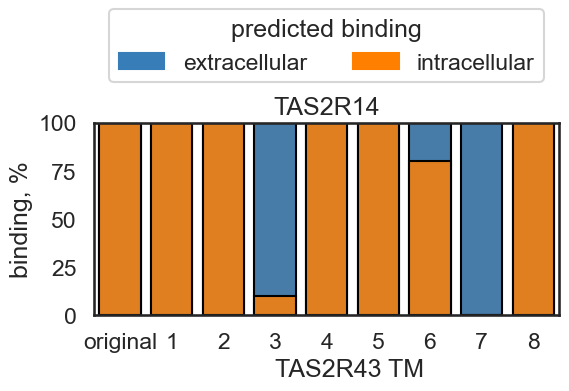

In [7]:
sns.set(rc={'figure.figsize':(6, 2.5)}, style='white', context='talk')

source_receptor = 'TAS2R14'
target_receptor = 'TAS2R43'

sub_df = tm_replacement_results[tm_replacement_results['source receptor'] == source_receptor].reset_index(drop=True)

intracellular = sub_df[sub_df['binding pocket'] == 'intracellular'].reset_index(drop=True)
bar_extracellular = sns.barplot(intracellular, x='target receptor TM', y='total', color=palette[1], legend=False, edgecolor='black')
bar_intracellular = sns.barplot(intracellular, x='target receptor TM', y='binding', color=palette[4], legend=False, edgecolor='black')
bar_intracellular.set(ylabel='binding, %', xlabel=f'{target_receptor} TM', ylim=(0, 100), title=source_receptor)
bar_intracellular.xaxis.label.set_position((0.55, -0.1))

# add legend
top_bar = mpatches.Patch(color=palette[1], label='extracellular')
bottom_bar = mpatches.Patch(color=palette[4], label='intracellular')
bar_extracellular.legend(handles=[top_bar, bottom_bar], title='predicted binding')
sns.move_legend(bar_extracellular, 'center', bbox_to_anchor=(0.5, 1.4), ncol=2)

bar_extracellular.figure.savefig(f'../figures/main/Figure 2E {source_receptor} TM replacement.png', dpi=300, bbox_inches='tight')

### TAS2R43

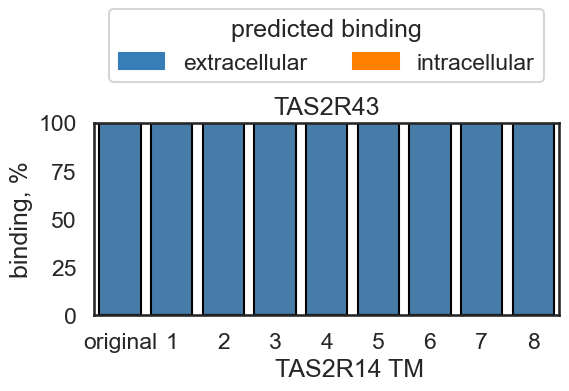

In [8]:
sns.set(rc={'figure.figsize':(6, 2.5)}, style='white', context='talk')

source_receptor = 'TAS2R43'
target_receptor = 'TAS2R14'

sub_df = tm_replacement_results[tm_replacement_results['source receptor'] == source_receptor].reset_index(drop=True)

intracellular = sub_df[sub_df['binding pocket'] == 'intracellular'].reset_index(drop=True)
bar_extracellular = sns.barplot(intracellular, x='target receptor TM', y='total', color=palette[1], legend=False, edgecolor='black')
bar_intracellular = sns.barplot(intracellular, x='target receptor TM', y='binding', color=palette[4], legend=False, edgecolor='black')
bar_intracellular.set(ylabel='binding, %', xlabel=f'{target_receptor} TM', ylim=(0, 100), title=source_receptor)
bar_intracellular.xaxis.label.set_position((0.55, -0.1))

# add legend
top_bar = mpatches.Patch(color=palette[1], label='extracellular')
bottom_bar = mpatches.Patch(color=palette[4], label='intracellular')
bar_extracellular.legend(handles=[top_bar, bottom_bar], title='predicted binding')
sns.move_legend(bar_extracellular, 'center', bbox_to_anchor=(0.5, 1.4), ncol=2)

bar_extracellular.figure.savefig(f'../figures/main/Figure 2E {source_receptor} TM replacement.png', dpi=300, bbox_inches='tight')

### Supplementary Figure 3

In [16]:
from pymsaviz import MsaViz

color_palette_template = {'#fb8072': ['D', 'E'], # red
                          '#fdb462': ['F', 'Y', 'W'], # orange
                          '#ffffb3': ['C'], # yellow
                          '#b3de69': ['S', 'T', 'N', 'Q'], # green
                          '#80b1d3': ['R', 'H', 'K'], # blue
                          '#bebada': ['G', 'P'], # purple
                          '#d9d9d9': ['A', 'V', 'I', 'L', 'M']} # gray
custom_color_palette = {aa: color
                        for color, amino_acids in color_palette_template.items()
                        for aa in amino_acids}

In [17]:
path_to_file = '../data/hTAS2Rs_BW_numbers.xlsx'
BW_numbers = pd.read_excel(path_to_file, index_col='BW number').fillna('-').map(lambda el: el[0])
TM_numbers = BW_numbers.copy()
TM_numbers.index = pd.Index([int(el) for el in TM_numbers.index], name='TM number', dtype='int')

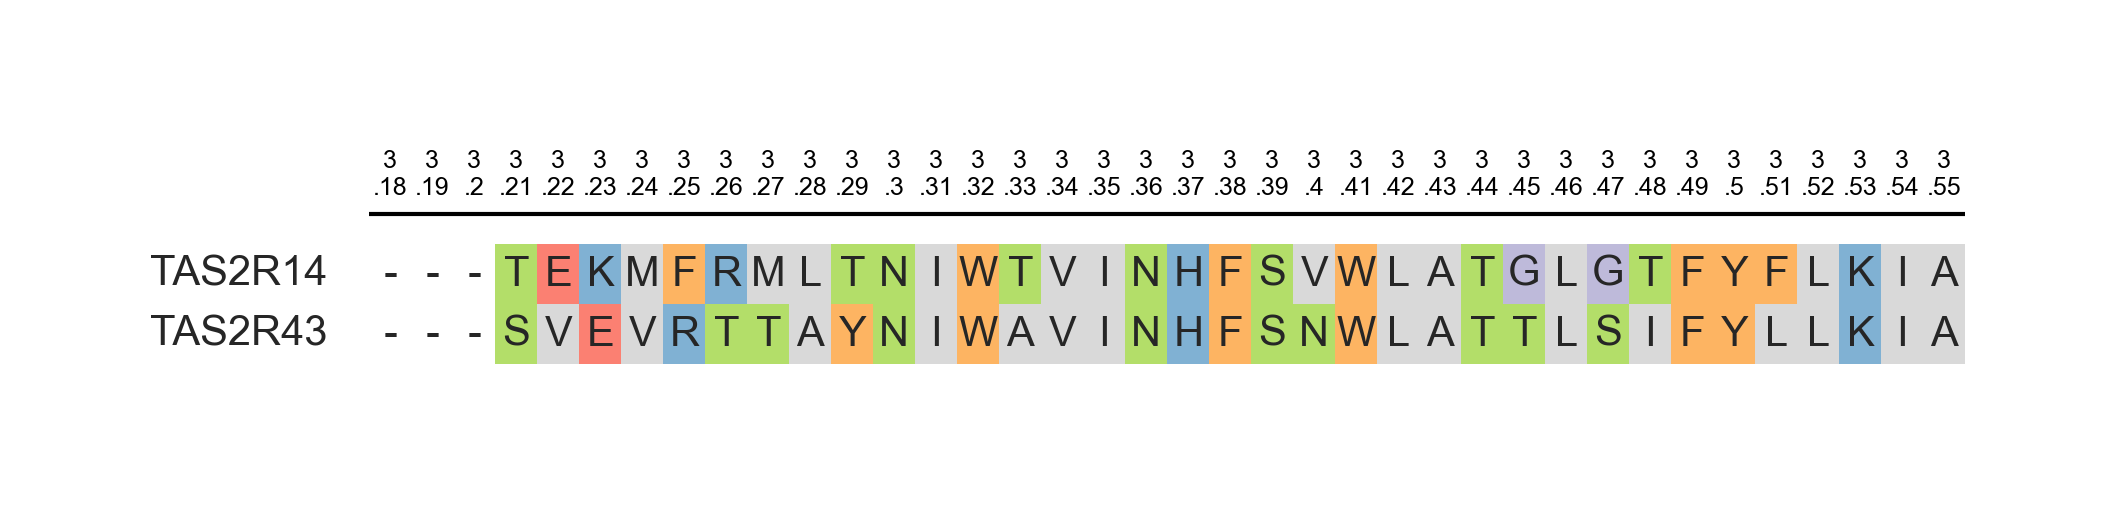

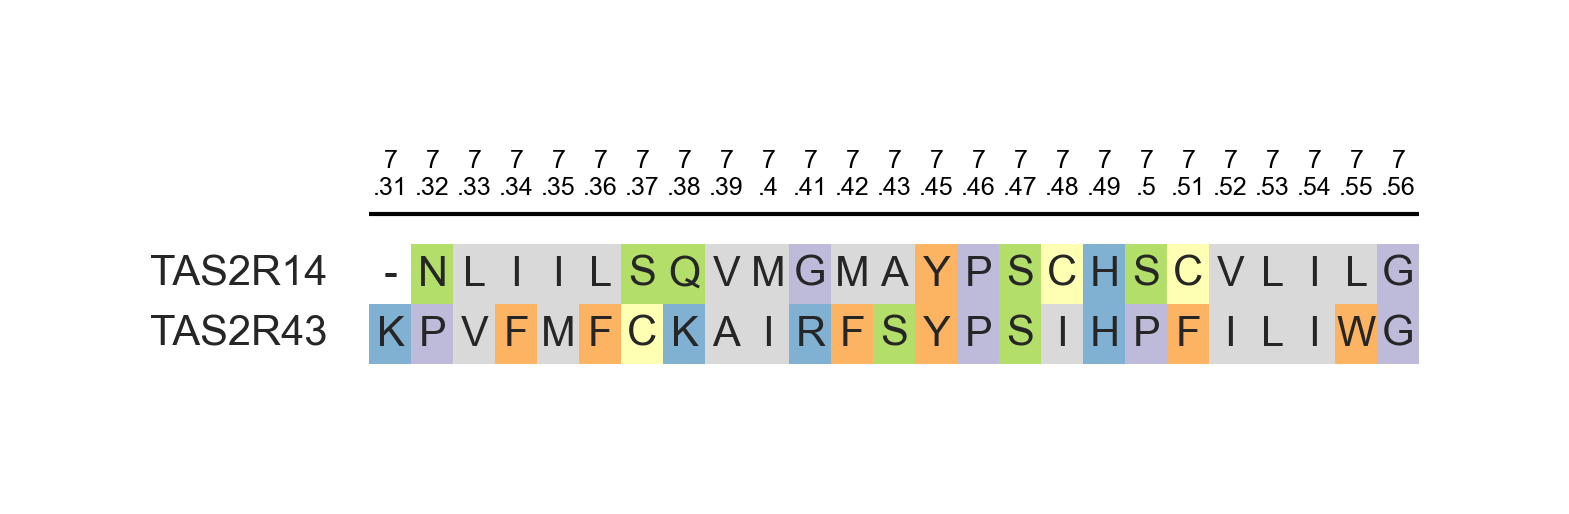

In [18]:
receptors = BW_numbers.columns.to_list()
selected_TAS2Rs = ['TAS2R14', 'TAS2R43']
selected_TMs = [3, 7]

for TM in selected_TMs:
    TM_df = BW_numbers[TM_numbers.index == TM].T
    TM_BW_numbers = TM_df.columns

    path_to_file = f'../data/msa/hTAS2Rs_TM{TM}_msa.fa'
    with open(path_to_file, 'w') as out:
        for receptor in selected_TAS2Rs:
            receptor_TM_df = TM_df.loc[receptor]
            receptor_msa_sequence = ''.join(receptor_TM_df)
            out.write(f'>{receptor}\n{receptor_msa_sequence}\n')

    mv = MsaViz(path_to_file, show_consensus=False, consensus_color='#377eb8')
    mv.set_custom_color_scheme(custom_color_palette)
    mv.set_plot_params(ticks_interval=None)

    # bw numbers
    for n, BW_number in enumerate(TM_BW_numbers, start=1):
        mv.add_text_annotation((n, n), str(BW_number).replace('.', '\n.'), text_color='black', range_color='black', text_size=6)
    fig = mv.plotfig(dpi=300)
    fig.savefig(f'../figures/supplementary/Supplementary Figure 3 Aligned sequences of TAS2R14 and TAS2R43 TM{TM}.png', dpi=300)